In [ ]:
!pip install torch torchvision torchaudio --index-url https://download.pytorch.org/whl/cpu

Загрузка необходимых библиотек

In [1]:
import torch
import torch.nn as nn

# from torch.utils.data import Dataset, DataLoader, random_split

# import torchvision
# from torchvision.transforms import v2

# import os
import numpy as np
import matplotlib.pyplot as plt
import torch.optim as optim

# import json
# from tqdm import tqdm
# from PIL import Image

# plt.style.use('dark_background')  # делает фон графиков темным

Цикл обучения
    Тренировка модели
        Данные
        Прямой проход + расчет ошибки модели
        Обратный проход
        Шаг оптимизации
    Расчет значения метрики
    Сохранение значения функции потерь и метрики

Проверка модели (валидация)
    Данные
    Прямой проход + расчет ошибки модели
Расчет значения метрики
Сохранение значения функции потерь и метрики


моя нейронка по теплопроводности, скопированная из колаба

    Аналитическое решение

    Параметры:
        x: np.ndarray
            Вектор координат x.
        y: np.ndarray
            Вектор координат y.
        t: np.ndarray
            Вектор координат t.
        bounds: dict
            Границы расчетной области.
        alpha: float
            Коэффициент температурапроводности материала.

    Возвращает:
        np.ndarray
            Вектор значений температур, являющихся аналитическим решением.

Пользуясь выводами из статьи[4] и используя за основу представленный авторами код реализуем линейный слой с синусоидальной функцией активации. Для достижения сходимости необходимо учесть особенности инициализации весов слоя и выбрать некоторые гиперпараметры, теоретическое обоснование этого процесса представлено в оригинальной статье https://arxiv.org/abs/2006.09661 и код на гитхабе https://github.com/vsitzmann/siren


In [2]:
def analytical_solution(x: np.ndarray,
                        y: np.ndarray,
                        t: np.ndarray,
                        bounds: dict,
                        alpha: float) -> np.ndarray:

    u = (np.sin(np.pi * x / bounds['x']) * np.sin(np.pi * y / bounds['y'])
         * np.exp(-2 * np.pi ** 2 * alpha * t / (bounds['x'] * bounds['y'])))

    return u

    Слой нейронной сети с синусоидальной функцией активации.

    Параметры:
        in_features: int
            Количество входных признаков.
        out_features: int
            Количество выходных признаков.
        bias: bool
            Использовать ли смещение в линейном слое.
        is_first: bool
            Является ли слой первым в сети.
        omega_0: float
            Частота для функции синуса.
    """
Строка 1. Определение класса SinLayer, который представляет собой слой нейронной сети с синусоидальной функцией активации.

Строки 17-22. Определение конструктора класса init, который принимает параметры слоя.

Строки 23-27. Инициализация параметров omega_0, is_first, in_features и создание линейного слоя (torch.nn.Linear).

Строка 28. Вызов метода init_weights(), который задает начальные значения весов.

Строка 30. Определение метода init_weights(), который устанавливает начальные значения весов линейного слоя.

Строки 35-37. Если слой является первым (is_first = True), веса инициализируются равномерно в диапазоне

.

Строка 38-42. В противном случае веса инициализируются в диапазоне

, что улучшает сходимость при обучении сети.

Строка 44. Определение метода forward(), который выполняет прямой проход через слой.

Строка 56. Применение линейного слоя к входным данным, умножение результата на частоту omega_0 и передача в функцию torch.sin(), реализующую синусоидальную активацию.

Подобные слой используется в архитектурах нейросетей, таких как SIREN (Sinusoidal Representation Networks), и позволяют эффективно аппроксимировать широкий спектр частот зависимостей в данных различных типов.

In [3]:
class SinLayer(torch.nn.Module):
    
    def __init__(self,
                 input: float,
                 output: float,
                 bias: bool=True,
                 is_first: bool=False,
                 omega_0: float=30):
        super().__init__()
        self.omega_0 = omega_0
        self.is_first = is_first
        self.in_features = input
        self.linear = torch.nn.Linear(input, output, bias=bias)
        self.init_weights()

    def init_weights(self):  #    Инициализация весов линейного слоя
        with torch.no_grad():
            if self.is_first:
                self.linear.weight.uniform_(-1 / self.in_features,
                                            1 / self.in_features)
            else:
                self.linear.weight.uniform_(-np.sqrt(6 / self.in_features)
                                            / self.omega_0,
                                            np.sqrt(6 / self.in_features)
                                            / self.omega_0)

    def forward(self, input): # Прямой проход через слой.  Параметры:  input: torch.Tensor Входной тензор.  Возвращает:torch.Tensor       Результат применения синусоидальной функции активации
        return torch.sin(self.omega_0 * self.linear(input))

    Физически-информированная нейронная сеть (PINN) с функцией активации синус.

    Параметры:
        layers: nn.ModuleList
            Список слоёв нейронной сети.
    
        Прямой проход через сеть.

        Параметры:
            x: torch.Tensor
                Тензор координат x.
            y: torch.Tensor
                Тензор координат y.
            t: torch.Tensor
                Тензор время t.

        Возвращает:
            torch.Tensor
                Выход сети.
        """

Строка 1: Объявление класса SinPINN, который наследует функциональность от базового класса nn.Module библиотеки PyTorch. Это обеспечивает возможность использовать все встроенные механизмы для построения и обучения нейронных сетей.

Строка 9: Объявление конструктора класса, который принимает layers — список определяющий количество нейронов для каждого слоя сети.

Строка 11: Вызов конструктора базового класса nn.Module для корректной инициализации всех внутренних механизмов PyTorch, необходимых для работы с нейронными сетями.

Строка 12: Инициализация объекта ModuleList для хранения слоёв нейронной сети. Использование ModuleList позволяет автоматически регистрировать параметры всех добавляемых слоёв.

Строки 13–22: Цикл по индексам списка layers создающий слои нейросети. Отдельно проверяется, является ли слой первым в сети. Если это условие выполнено, создаётся SinLayer с флагом is_first=True. Если же встречается последний слой — создаётся обычный Linear слой без синусоидальной функции активации. В остальных случаях создаётся SinLayer с is_first=False.

Строка 24: Объявление метода forward, который задаёт порядок прохождения входных данных через сеть. Этот метод принимает на вход тензоры $x, y$ и $t$ и возвращает предсказание модели (температуру).

Строки 43-45: Объединение входных данных (координаты $x, y$ и время $t$) в один тензор. Данные преобразуются из векторов в 2D-тензоры размерности (-1, 1) и конкатенируются вдоль оси dim=1, то есть вдоль оси столбцов. В итоге получится матрица, в строках которой записаны определенные состояния системы $(x_i, y_i, t_i)$


In [4]:
class SinPINN(nn.Module):
    
    def __init__(self,
                 layers: list):
        super().__init__()
        self.layers = nn.ModuleList()
        for i in range(len(layers) - 1):
            if i == 0:
                self.layers.append(SinLayer(layers[i],
                                            layers[i+1], is_first=True))
            elif i == len(layers) - 2:
                self.layers.append(nn.Linear(layers[i],
                                             layers[i+1],))
            else:
                self.layers.append(SinLayer(layers[i],
                                            layers[i+1], is_first=False))

    def forward(self,
                x: torch.Tensor,
                y: torch.Tensor,
                t: torch.Tensor) -> torch.Tensor:

        inputs = torch.cat([x.reshape(-1, 1),
                            y.reshape(-1, 1),
                            t.reshape(-1, 1)], dim=1)
        for layer in self.layers:
            inputs = layer(inputs)
        return inputs

Функция потерь для уравнения
    """
    Вычисляет остаток по уравнению теплопроводности для модели PINN.
    Вид уравнения:
        u_t - alpha * (u_xx + u_yy) = 0

    Параметры:
        model: torch.nn.Module
            Модель, вычисляющая u(x, y, t).
        x: torch.Tensor
            Тензор координаты x.
        y: torch.Tensor
            Тензор координаты y.
        t: torch.Tensor
            Тензор времени t.
        alpha: float
            Коэффициент теплопроводности.

    Возвращает:
        torch.Tensor
            Остаток уравнения f = u_t - alpha*(u_xx + u_yy).
    """

Строка 1. Объявление функции pde_residual, которая принимает в качестве аргументов модель, тензоры точек по координатам и времени для вычисления остатков (невязки) уравнения. Функция возвращает итоговое значение функции потерь на уравнении.

Строка 27. Вычисление значения выхода модели $u(x,y,t)$.

Строка 29-31. Вычисление первых производных $u_x, u_y, u_t$ с помощью функции автодифференцирования torch.autograd.grad. Параметр grad_outputs=torch.ones_like(u) указывает, что производная рассчитывается для каждого элемента тензора $u$. Флаг create_graph=True позволяет строить вычислительный граф для дальнейшего дифференцирования, что необходимо для вычисления второй производной.

Строка 33-35. Вычисление вторых производных $u_{xx}, u_{yy}$ и по $x$ и $y$ соответственно, используя torch.autograd.grad аналогичным образом.

Строка 38. Вычисление остатка уравнения теплопроводности. Если предсказания модели удовлетворяет физическому уравнению (2) $f = u_t - α (u_{xx} + u_{yy})$,
 должно стремиться к нулю.

Строка 39. Возвращение результата f, который затем будет использован для обучения PINN.

In [5]:
def pde_residual(model: SinPINN,   #Функция потерь для уравнения
                 x: torch.Tensor,
                 y: torch.Tensor,
                 t: torch.Tensor,
                 alpha: float):
    u = model(x, y, t)

    u_x, u_y, u_t = torch.autograd.grad(u, [x, y, t],
                                        grad_outputs=torch.ones_like(u),
                                        create_graph=True)

    u_xx = torch.autograd.grad(u_x, x, grad_outputs=torch.ones_like(u_x),
                               create_graph=True)[0]
    u_yy = torch.autograd.grad(u_y, y, grad_outputs=torch.ones_like(u_y),
                               create_graph=True)[0]

    f = u_t - alpha * (u_xx + u_yy)
    return f

    """
    Генерирует точки коллокации для уравнения PDE.

    Параметры:
        n: int
            Число точек коллокации.
        bounds: dict
            Границы области.
        device: torch.device
            Устройство (CPU или GPU).

    Возвращает:
        Tuple[torch.Tensor, torch.Tensor, torch.Tensor]
            Тензоры x, y, t с requires_grad=True.
    """

In [6]:
def generate_pde_points(n: int,
                        bounds: dict,
                        device: torch.device):
    x = (bounds['x'] * torch.rand(n, 1, device=device)).requires_grad_()
    y = (bounds['y'] * torch.rand(n, 1, device=device)).requires_grad_()
    t = (bounds['t'] * torch.rand(n, 1, device=device)).requires_grad_()
    return x, y, t

    """
    Генерирует точки коллокации для начального условия.

    Параметры:
        n: int
            Число точек начального условия.
        bounds: dict
            Границы расчетной области.
        device: torch.device
            Устройство (CPU или GPU).

    Возвращает:
        Tuple[torch.Tensor, torch.Tensor, torch.Tensor, torch.Tensor]:
            Тензоры x, y, t, u,
            где t — нулевой тензор, а u = sin(pi * x/L) * sin(pi * y/L).
    """

In [7]:
def generate_initial_condition(n: int,
                               bounds: dict,
                               device: torch.device):

    x = bounds['x'] * torch.rand(n, 1, device=device)
    y = bounds['y'] * torch.rand(n, 1, device=device)
    t = torch.zeros_like(x, device=device)
    u = torch.sin(np.pi * x/bounds['x']) * torch.sin(np.pi * y/bounds['y'])
    return x, y, t, u

    """
    Генерирует точки граничных условий.

    Параметры:
        n_b: int
            Число точек для граничных условий.
        bounds: dict
            Границы области, например, {'x': 1.0, 'y': 1.0, 't': 1.0}.
        device: torch.device
            Устройство (CPU или GPU).

    Возвращает:
        Tuple[torch.Tensor, torch.Tensor, torch.Tensor, torch.Tensor]:
            x_b, y_b, t_b, u_b, где u_b = 0.
    """

In [8]:
def generate_boundary_conditions(n: int,
                                 bounds: dict,
                                 device: torch.device):

    x = bounds['x'] * torch.rand(n, 1, device=device)
    y = bounds['y'] * torch.rand(n, 1, device=device)
    t = bounds['t'] * torch.rand(n, 1, device=device)

    border_selector = torch.randint(0, 4, (n, 1), device=device)
    x[border_selector == 0] = 0.0 # Left bound
    x[border_selector == 1] = bounds['x'] # Right bound
    y[border_selector == 2] = 0.0 # Bottom bound
    y[border_selector == 3] = bounds['y'] # Upper bound

    u_b = torch.zeros_like(t, device=device)
    return x, y, t, u_b

In [9]:
torch.manual_seed(42)
np.random.seed(42)

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

N_F, N_B, N_I = 10000, 5000, 2000
BOUNDS = {'x': 0.1, 'y': 0.1, 't': 12.0}
ALPHA = 1.12 * 1e-4

model = SinPINN([3, 64, 1]).to(device)
mse_loss = nn.MSELoss()
optimizer = optim.Adam(model.parameters(), lr=1e-3)

x_f, y_f, t_f = generate_pde_points(N_F, BOUNDS, device)
x_i, y_i, t_i, u_i = generate_initial_condition(N_I, BOUNDS, device)
x_b, y_b, t_b, u_b = generate_boundary_conditions(N_B, BOUNDS, device)

w_pde, w_bc, w_ic = 10.0, 1.0, 1.0

Цикл обучения

In [10]:
epochs = 1000

loss_history = {'pde': [],
                'ic': [],
                'bc': []}

for epoch in range(epochs+1):
    optimizer.zero_grad()

    u_pred_i = model(x_i, y_i, t_i)
    loss_ic = mse_loss(u_pred_i, u_i)  # потери на начальных условиях (ic - initial conditions)

    u_pred_b = model(x_b, y_b, t_b)
    loss_bc = mse_loss(u_pred_b, u_b)  # потери на граничных условиях (bc - boundary conditions)

    loss_pde = mse_loss(pde_residual(model, x_f, y_f, t_f, ALPHA),
                        torch.zeros_like(x_f))  # потери модели по реализованной функции

    loss = w_ic * loss_ic + w_bc * loss_bc + w_pde * loss_pde

    loss.backward()
    optimizer.step()

    loss_history['ic'].append(loss_ic.item())
    loss_history['bc'].append(loss_bc.item())
    loss_history['pde'].append(loss_pde.item())

    if epoch % 100 == 0:
        print(f"Epoch {epoch}, Loss: {loss.item():.3e}, "
              f"IC: {loss_ic.item():.3e}, "
              f"BC: {loss_bc.item():.3e}, "
              f"PDE: {loss_pde.item():.3e}")

Epoch 0, Loss: 5.218e+01, IC: 7.245e-01, BC: 1.259e-01, PDE: 5.133e+00
Epoch 100, Loss: 4.359e-01, IC: 9.151e-02, BC: 1.615e-02, PDE: 3.283e-02
Epoch 200, Loss: 2.088e-01, IC: 8.866e-02, BC: 1.495e-02, PDE: 1.052e-02
Epoch 300, Loss: 1.449e-01, IC: 8.384e-02, BC: 1.434e-02, PDE: 4.670e-03
Epoch 400, Loss: 1.105e-01, IC: 7.249e-02, BC: 1.351e-02, PDE: 2.453e-03
Epoch 500, Loss: 7.783e-02, IC: 5.261e-02, BC: 1.255e-02, PDE: 1.267e-03
Epoch 600, Loss: 4.920e-02, IC: 3.106e-02, BC: 9.328e-03, PDE: 8.815e-04
Epoch 700, Loss: 3.629e-02, IC: 1.867e-02, BC: 7.376e-03, PDE: 1.025e-03
Epoch 800, Loss: 2.825e-02, IC: 1.322e-02, BC: 5.577e-03, PDE: 9.455e-04
Epoch 900, Loss: 1.931e-02, IC: 8.430e-03, BC: 3.528e-03, PDE: 7.351e-04
Epoch 1000, Loss: 1.303e-02, IC: 4.988e-03, BC: 2.219e-03, PDE: 5.827e-04


    """
    Функция для построения графика функции потерь.

    Параметры:
        loss_history : dict
            Словарь, содержащий данные для потерь.
        step : int, optional
            Шаг выборки данных для отображения, по умолчанию 100.
    """

In [11]:
def plot_loss_history(loss_history: dict,
                      step: int=200):

    epochs = range(0, len(loss_history['pde']), step)

    plt.plot(epochs, loss_history['pde'][::step], label='PDE Loss')
    plt.plot(epochs, loss_history['bc'][::step], label='BC Loss')
    plt.plot(epochs, loss_history['ic'][::step], label='IC Loss')

    plt.yscale('log')
    plt.xlabel('Epoch')
    plt.ylabel('Loss')
    plt.grid()
    plt.legend()
    plt.show()

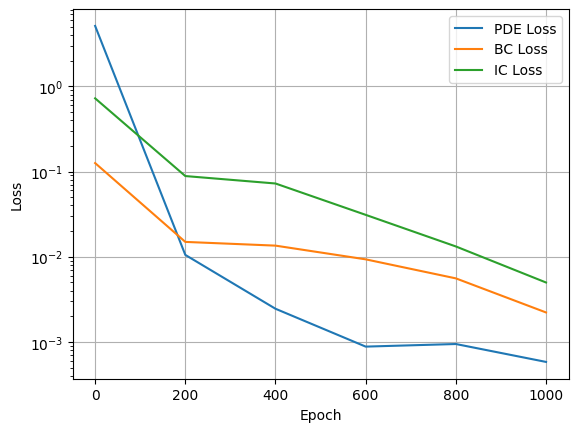

In [12]:
plot_loss_history(loss_history)